In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings("ignore")

In [ ]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset Shape:", X.shape)

print("\nFirst 5 rows:")
display(X.head())

print("\nTarget Classes:")
print(data.target_names)

print("\nClass Distribution:")
print(y.value_counts())

Dataset Shape: (569, 30)

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target Classes:
['malignant' 'benign']

Class Distribution:
target
1    357
0    212
Name: count, dtype: int64


In [ ]:
print("Missing values:")
print(X.isnull().sum().sum())

Missing values:
0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [ ]:
dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(X_train, y_train)

train_pred = dt.predict(X_train)
test_pred = dt.predict(X_test)

train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

print("Decision Tree")
print("----------------------")
print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Decision Tree
----------------------
Training Accuracy: 1.0
Testing Accuracy : 0.9122807017543859


In [ ]:
depths = range(1, 21)

train_scores = []
test_scores = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_scores.append(
        model.score(X_train, y_train)
    )

    test_scores.append(
        model.score(X_test, y_test)
    )

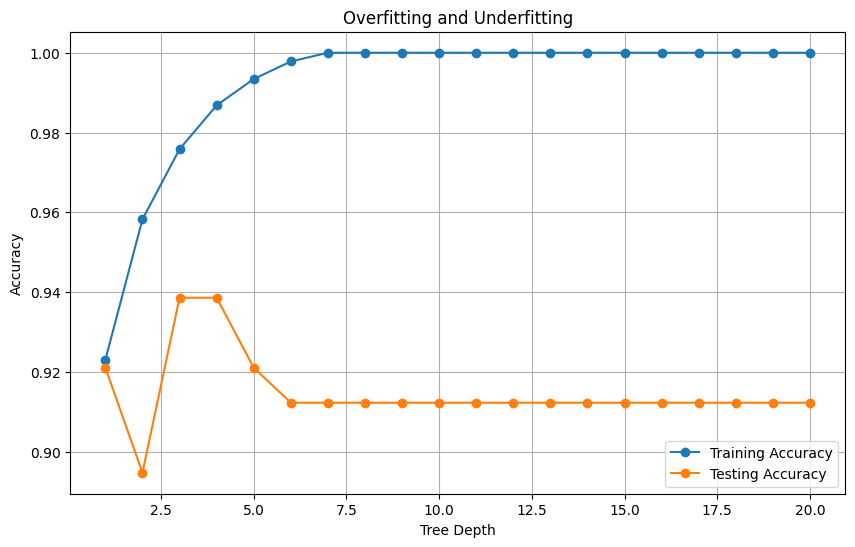

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    depths,
    train_scores,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    depths,
    test_scores,
    marker='o',
    label='Testing Accuracy'
)

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting and Underfitting")
plt.legend()
plt.grid()

plt.show()

In [ ]:
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    random_state=42
)

bagging.fit(X_train, y_train)

bag_train_pred = bagging.predict(X_train)
bag_test_pred = bagging.predict(X_test)

print("Bagging")
print("----------------------")
print("Training Accuracy:",
      accuracy_score(y_train, bag_train_pred))

print("Testing Accuracy :",
      accuracy_score(y_test, bag_test_pred))

Bagging
----------------------
Training Accuracy: 1.0
Testing Accuracy : 0.9473684210526315


In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_train_pred = rf.predict(X_train)
rf_test_pred = rf.predict(X_test)

print("Random Forest")
print("----------------------")
print("Training Accuracy:",
      accuracy_score(y_train, rf_train_pred))

print("Testing Accuracy :",
      accuracy_score(y_test, rf_test_pred))

Random Forest
----------------------
Training Accuracy: 1.0
Testing Accuracy : 0.956140350877193


In [ ]:
!pip install xgboost -q

In [ ]:
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0,
    reg_lambda=1,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train, y_train)

xgb_train_pred = xgb.predict(X_train)
xgb_test_pred = xgb.predict(X_test)

print("XGBoost")
print("----------------------")
print("Training Accuracy:",
      accuracy_score(y_train, xgb_train_pred))

print("Testing Accuracy :",
      accuracy_score(y_test, xgb_test_pred))

XGBoost
----------------------
Training Accuracy: 0.9956043956043956
Testing Accuracy : 0.9473684210526315


In [ ]:
!pip install lightgbm -q

In [ ]:
lgbm = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0,
    reg_lambda=1,
    random_state=42,
    verbosity=-1
)

lgbm.fit(X_train, y_train)

lgbm_train_pred = lgbm.predict(X_train)
lgbm_test_pred = lgbm.predict(X_test)

print("LightGBM")
print("----------------------")
print("Training Accuracy:",
      accuracy_score(y_train, lgbm_train_pred))

print("Testing Accuracy :",
      accuracy_score(y_test, lgbm_test_pred))

LightGBM
----------------------
Training Accuracy: 0.9934065934065934
Testing Accuracy : 0.956140350877193


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Bagging",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],

    "Training Accuracy": [
        train_acc,
        accuracy_score(y_train, bag_train_pred),
        accuracy_score(y_train, rf_train_pred),
        accuracy_score(y_train, xgb_train_pred),
        accuracy_score(y_train, lgbm_train_pred)
    ],

    "Testing Accuracy": [
        test_acc,
        accuracy_score(y_test, bag_test_pred),
        accuracy_score(y_test, rf_test_pred),
        accuracy_score(y_test, xgb_test_pred),
        accuracy_score(y_test, lgbm_test_pred)
    ]
})

display(results)

,Model,Training Accuracy,Testing Accuracy
0,Decision Tree,1.000000,0.912281
1,Bagging,1.000000,0.947368
2,Random Forest,1.000000,0.956140
3,XGBoost,0.995604,0.947368
4,LightGBM,0.993407,0.956140


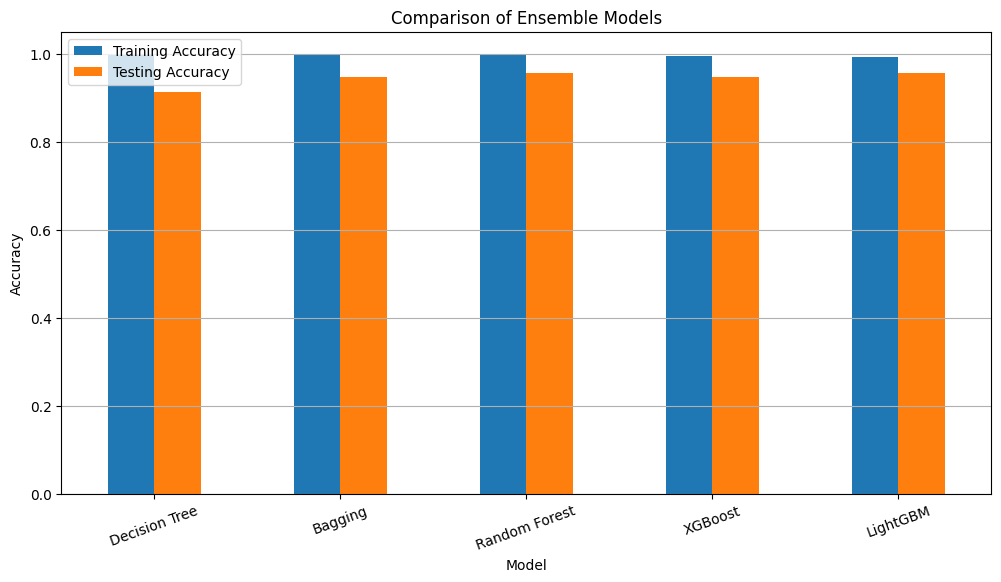

In [ ]:
results.plot(
    x="Model",
    y=["Training Accuracy", "Testing Accuracy"],
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Ensemble Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.grid(axis='y')

plt.show()

In [ ]:
depths = range(1, 16)

bias_variance_results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    bias_variance_results.append([
        depth,
        train_accuracy,
        test_accuracy,
        train_accuracy - test_accuracy
    ])

bv_df = pd.DataFrame(
    bias_variance_results,
    columns=[
        "Tree Depth",
        "Training Accuracy",
        "Testing Accuracy",
        "Train-Test Gap"
    ]
)

display(bv_df)

,Tree Depth,Training Accuracy,Testing Accuracy,Train-Test Gap
0,1,0.923077,0.921053,0.002024
1,2,0.958242,0.894737,0.063505
2,3,0.975824,0.938596,0.037228
3,4,0.986813,0.938596,0.048217
4,5,0.993407,0.921053,0.072354
5,6,0.997802,0.912281,0.085521
6,7,1.000000,0.912281,0.087719
7,8,1.000000,0.912281,0.087719
8,9,1.000000,0.912281,0.087719
9,10,1.000000,0.912281,0.087719


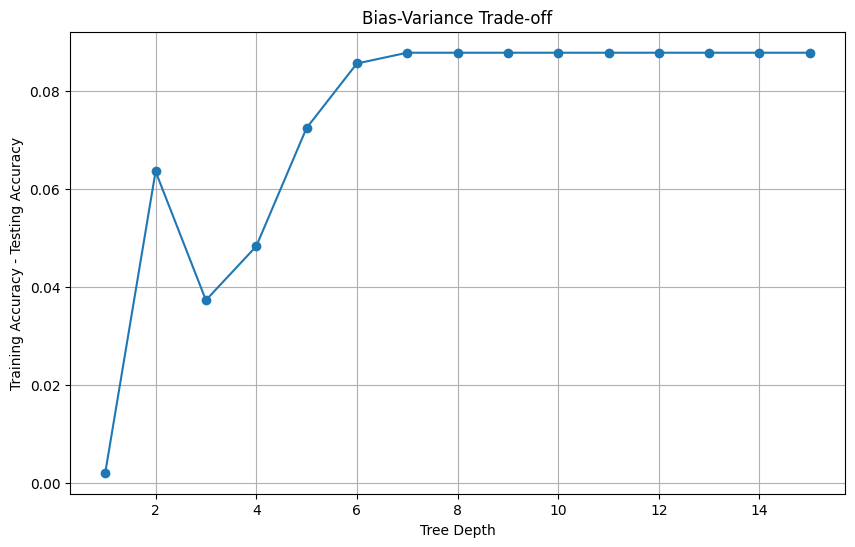

In [ ]:
 plt.figure(figsize=(10, 6))

plt.plot(
    bv_df["Tree Depth"],
    bv_df["Train-Test Gap"],
    marker="o"
)

plt.xlabel("Tree Depth")
plt.ylabel("Training Accuracy - Testing Accuracy")
plt.title("Bias-Variance Trade-off")
plt.grid()

plt.show()

In [ ]:
l1_values = [0, 0.1, 1, 10]

l1_results = []

for alpha in l1_values:

    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        reg_alpha=alpha,
        reg_lambda=0,
        random_state=42,
        eval_metric='logloss'
    )

    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

    l1_results.append([
        alpha,
        train_acc,
        test_acc
    ])

l1_df = pd.DataFrame(
    l1_results,
    columns=[
        "L1 (reg_alpha)",
        "Training Accuracy",
        "Testing Accuracy"
    ]
)

display(l1_df)

,L1 (reg_alpha),Training Accuracy,Testing Accuracy
0,0.0,1.000000,0.947368
1,0.1,0.997802,0.947368
2,1.0,0.993407,0.938596
3,10.0,0.986813,0.938596


In [ ]:
l2_values = [0, 0.1, 1, 10]

l2_results = []

for reg in l2_values:

    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        reg_alpha=0,
        reg_lambda=reg,
        random_state=42,
        eval_metric='logloss'
    )

    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

    l2_results.append([
        reg,
        train_acc,
        test_acc
    ])

l2_df = pd.DataFrame(
    l2_results,
    columns=[
        "L2 (reg_lambda)",
        "Training Accuracy",
        "Testing Accuracy"
    ]
)

display(l2_df)

,L2 (reg_lambda),Training Accuracy,Testing Accuracy
0,0.0,1.000000,0.947368
1,0.1,0.997802,0.947368
2,1.0,0.995604,0.947368
3,10.0,0.991209,0.947368


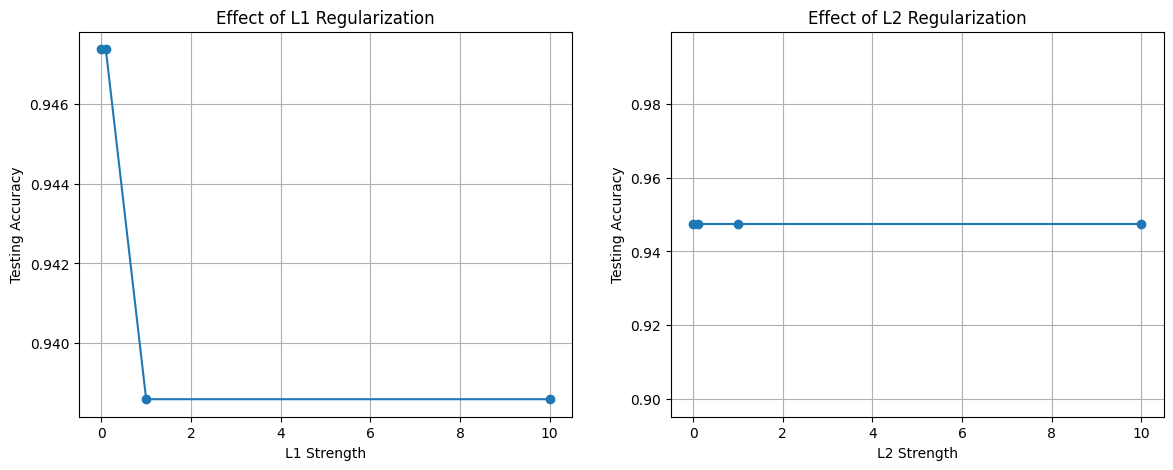

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    l1_df["L1 (reg_alpha)"],
    l1_df["Testing Accuracy"],
    marker="o"
)

axes[0].set_title("Effect of L1 Regularization")
axes[0].set_xlabel("L1 Strength")
axes[0].set_ylabel("Testing Accuracy")
axes[0].grid()

axes[1].plot(
    l2_df["L2 (reg_lambda)"],
    l2_df["Testing Accuracy"],
    marker="o"
)

axes[1].set_title("Effect of L2 Regularization")
axes[1].set_xlabel("L2 Strength")
axes[1].set_ylabel("Testing Accuracy")
axes[1].grid()

plt.show()

In [ ]:
print("XGBoost Classification Report")
print("=" * 40)

print(
    classification_report(
        y_test,
        xgb_test_pred,
        target_names=data.target_names
    )
)

XGBoost Classification Report
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



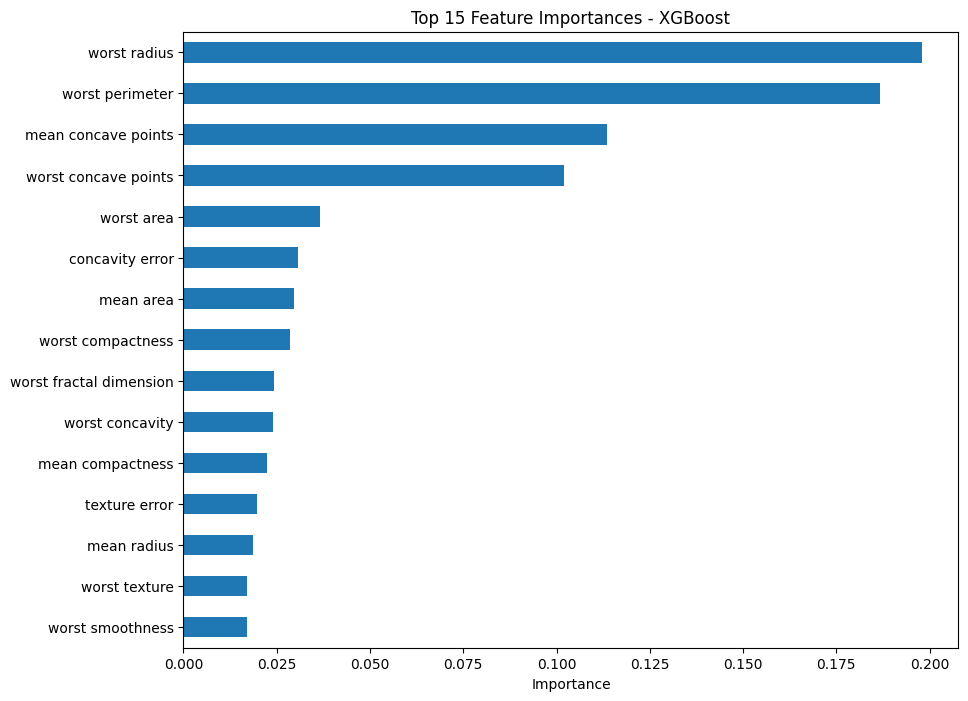

In [ ]:
importance = pd.Series(
    xgb.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))

importance.head(15).plot(kind="barh")

plt.title("Top 15 Feature Importances - XGBoost")
plt.xlabel("Importance")

plt.gca().invert_yaxis()

plt.show()